# Etap 4 — Analiza korelacji, dobór atrybutów i redukcja wymiarowości

**Autorzy:** Adrian Tusiński, Aleksander Klank

**Cel:** poznanie metod korelacyjnych oraz redukcji wymiarowości.
**Rezultat etapu:** zastosowanie metod korelacyjnych (pandas) i redukcji wymiarowości (scikit-learn: PCA, porównawczo LDA) wraz z analizą wyników.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src.utils import *  # ścieżki, wczytywanie danych, styl wykresów

set_plot_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler

In [2]:
sales = pd.read_csv(PROCESSED_DIR / "oferty_sprzedaz_clean.csv")
cities = pd.read_csv(PROCESSED_DIR / "miasta_wskazniki.csv")
print(sales.shape, cities.shape)

(91292, 43) (15, 38)


## 4.1 Korelacja — pojęcie i metody

**Korelacja** mierzy siłę i kierunek związku między dwiema zmiennymi; współczynnik przyjmuje wartości od −1 (idealny związek ujemny) przez 0 (brak związku) do +1 (idealny związek dodatni).
Korelacja **nie oznacza przyczynowości**.

| Metoda | Co mierzy | Założenia | Kiedy stosować |
|---|---|---|---|
| **Pearson** (r) | związek **liniowy** | zmienne ilościowe, rozkład zbliżony do normalnego, wrażliwy na wartości odstające | zależności liniowe |
| **Spearman** (ρ) | związek **monotoniczny** (na rangach) | zmienne co najmniej porządkowe, odporny na wartości odstające | rozkłady skośne, zależności nieliniowe, ale monotoniczne |
| **Kendall** (τ) | zgodność uporządkowania par | jak Spearman; dokładniejszy dla małych prób i wielu remisów | małe próby (np. 15 miast) |

Interpretacja siły (|r|): < 0,1 brak, 0,1–0,3 słaba, 0,3–0,5 umiarkowana, 0,5–0,7 silna, > 0,7 bardzo silna.

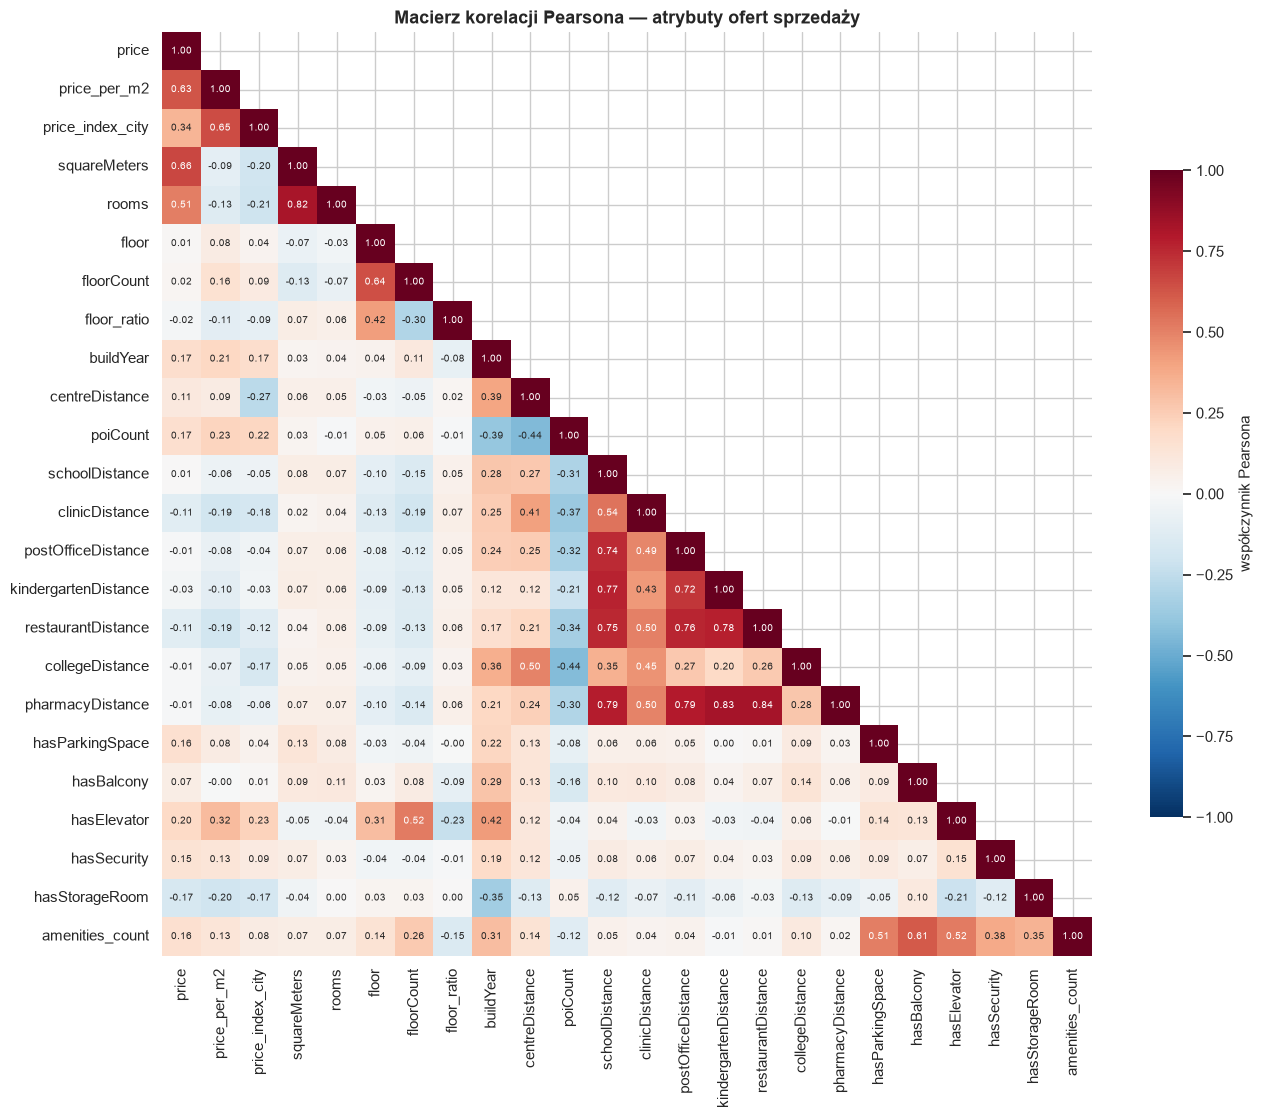

In [3]:
FEATURES = ["price", "price_per_m2", "price_index_city", "squareMeters", "rooms", "floor", "floorCount", "floor_ratio",
            "buildYear", "centreDistance", "poiCount", "schoolDistance", "clinicDistance", "postOfficeDistance",
            "kindergartenDistance", "restaurantDistance", "collegeDistance", "pharmacyDistance",
            "hasParkingSpace", "hasBalcony", "hasElevator", "hasSecurity", "hasStorageRoom", "amenities_count"]

pearson = sales[FEATURES].corr(method="pearson")
spearman = sales[FEATURES].corr(method="spearman")
kendall = sales[FEATURES].sample(10000, random_state=RANDOM_STATE).corr(method="kendall")  # Kendall jest O(n²) → próba 10 tys.

fig, ax = plt.subplots(figsize=(15, 12))
mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)
sns.heatmap(pearson, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "współczynnik Pearsona", "shrink": 0.7})
ax.set_title("Macierz korelacji Pearsona — atrybuty ofert sprzedaży")
save_fig(fig, "04_macierz_korelacji_pearson")
plt.show()

## 4.2 Porównanie metod korelacji dla ceny za m²

Za zmienną objaśnianą przyjmujemy **indeks ceny względem miasta** (`price_index_city`) — usuwa on różnice poziomu cen między miastami,
dzięki czemu widać wpływ cech samego mieszkania i lokalizacji w mieście (por. paradoks Simpsona z etapu 2).

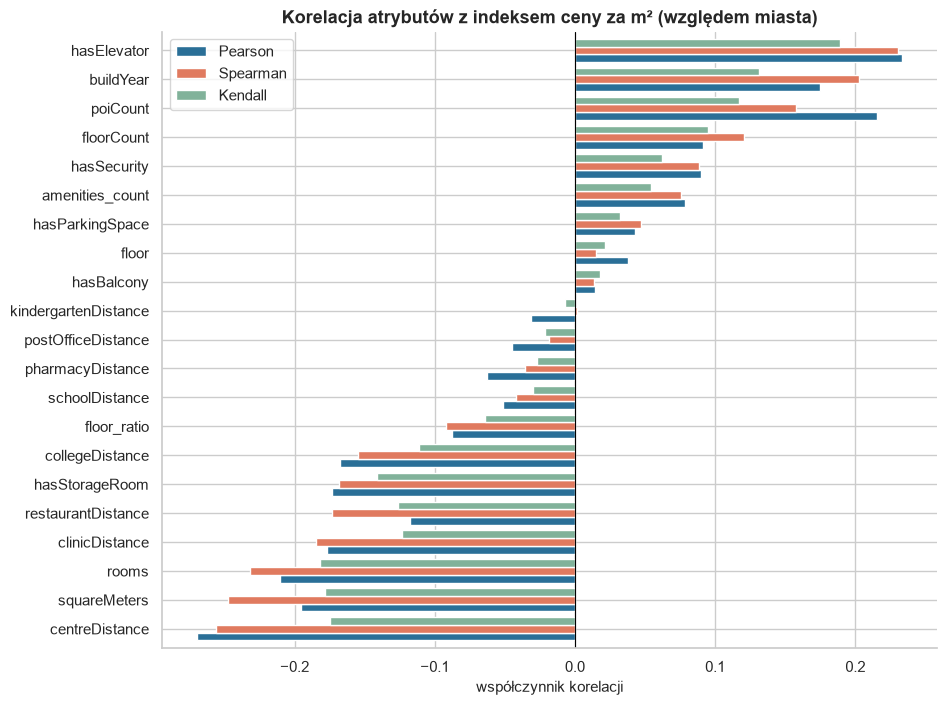

,Pearson,Spearman,Kendall
centreDistance,-0.27,-0.26,-0.17
squareMeters,-0.20,-0.25,-0.18
rooms,-0.21,-0.23,-0.18
hasElevator,0.23,0.23,0.19
buildYear,0.17,0.20,0.13
clinicDistance,-0.18,-0.18,-0.12
restaurantDistance,-0.12,-0.17,-0.13
hasStorageRoom,-0.17,-0.17,-0.14
poiCount,0.21,0.16,0.12
collegeDistance,-0.17,-0.15,-0.11


In [4]:
target = "price_index_city"
drop = ["price", "price_per_m2", "price_index_city"]
methods = pd.DataFrame({
    "Pearson": pearson[target], "Spearman": spearman[target], "Kendall": kendall[target],
}).drop(drop).sort_values("Spearman")

fig, ax = plt.subplots(figsize=(10, 8))
methods.plot(kind="barh", ax=ax, width=0.8, color=["#2a6f97", "#e07a5f", "#81b29a"])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Korelacja atrybutów z indeksem ceny za m² (względem miasta)")
ax.set_xlabel("współczynnik korelacji")
save_fig(fig, "04_korelacja_metody_porownanie")
plt.show()
methods.sort_values("Spearman", key=abs, ascending=False).round(3)

In [5]:
# Istotność statystyczna wybranych korelacji (test dla H0: brak korelacji)
pairs = [("centreDistance", target), ("buildYear", target), ("poiCount", target), ("hasElevator", target),
         ("squareMeters", "price"), ("squareMeters", "rooms"), ("floorCount", "hasElevator")]
rows = []
for a, b in pairs:
    r, p_r = stats.pearsonr(sales[a], sales[b])
    rho, p_rho = stats.spearmanr(sales[a], sales[b])
    rows.append({"para": f"{a} ~ {b}", "Pearson r": r, "p (Pearson)": p_r, "Spearman ρ": rho, "p (Spearman)": p_rho})
pd.DataFrame(rows).style.format({"Pearson r": "{:.3f}", "Spearman ρ": "{:.3f}", "p (Pearson)": "{:.1e}", "p (Spearman)": "{:.1e}"})

,para,Pearson r,p (Pearson),Spearman ρ,p (Spearman)
0,centreDistance ~ price_index_city,-0.269,0.0e+00,-0.256,0.0e+00
1,buildYear ~ price_index_city,0.175,0.0e+00,0.202,0.0e+00
2,poiCount ~ price_index_city,0.215,0.0e+00,0.157,0.0e+00
3,hasElevator ~ price_index_city,0.233,0.0e+00,0.230,0.0e+00
4,squareMeters ~ price,0.664,0.0e+00,0.597,0.0e+00
5,squareMeters ~ rooms,0.825,0.0e+00,0.823,0.0e+00
6,floorCount ~ hasElevator,0.518,0.0e+00,0.581,0.0e+00


**Wnioski (poziom ofert):**
- Najsilniej z ceną za m² (względem miasta) wiążą się: **odległość od centrum** (ujemnie, r ≈ −0,27), **winda** (+0,23), **liczba usług w promieniu 500 m** (+0,21) i **rok budowy** (+0,17…+0,20).
  Ujemna korelacja z metrażem i liczbą pokoi oznacza, że **większe mieszkania są tańsze w przeliczeniu na m²**.
- Wszystkie korelacje pojedynczych atrybutów są **słabe lub umiarkowane** (|r| < 0,3) — cena zależy od wielu czynników naraz, więc potrzebny jest model wielowymiarowy (etap 5).
- Pearson i Spearman dają zbliżone wyniki (zależności w przybliżeniu monotoniczne); dla metrażu Spearman jest silniejszy (−0,25 vs −0,20) → zależność nieliniowa.
  Kendall ma z definicji mniejsze wartości bezwzględne (inna skala), ale ten sam kierunek i kolejność.
- Przy ~90 tys. obserwacji nawet słabe korelacje są statystycznie istotne (p ≈ 0) — o znaczeniu praktycznym decyduje **siła** współczynnika, nie p-wartość.

## 4.3 Korelacje na poziomie miast (pytanie 5)

Czy miasta z wyższymi zarobkami są bardziej czy mniej dostępne? Przy n = 15 stosujemy także Kendall (mała próba).

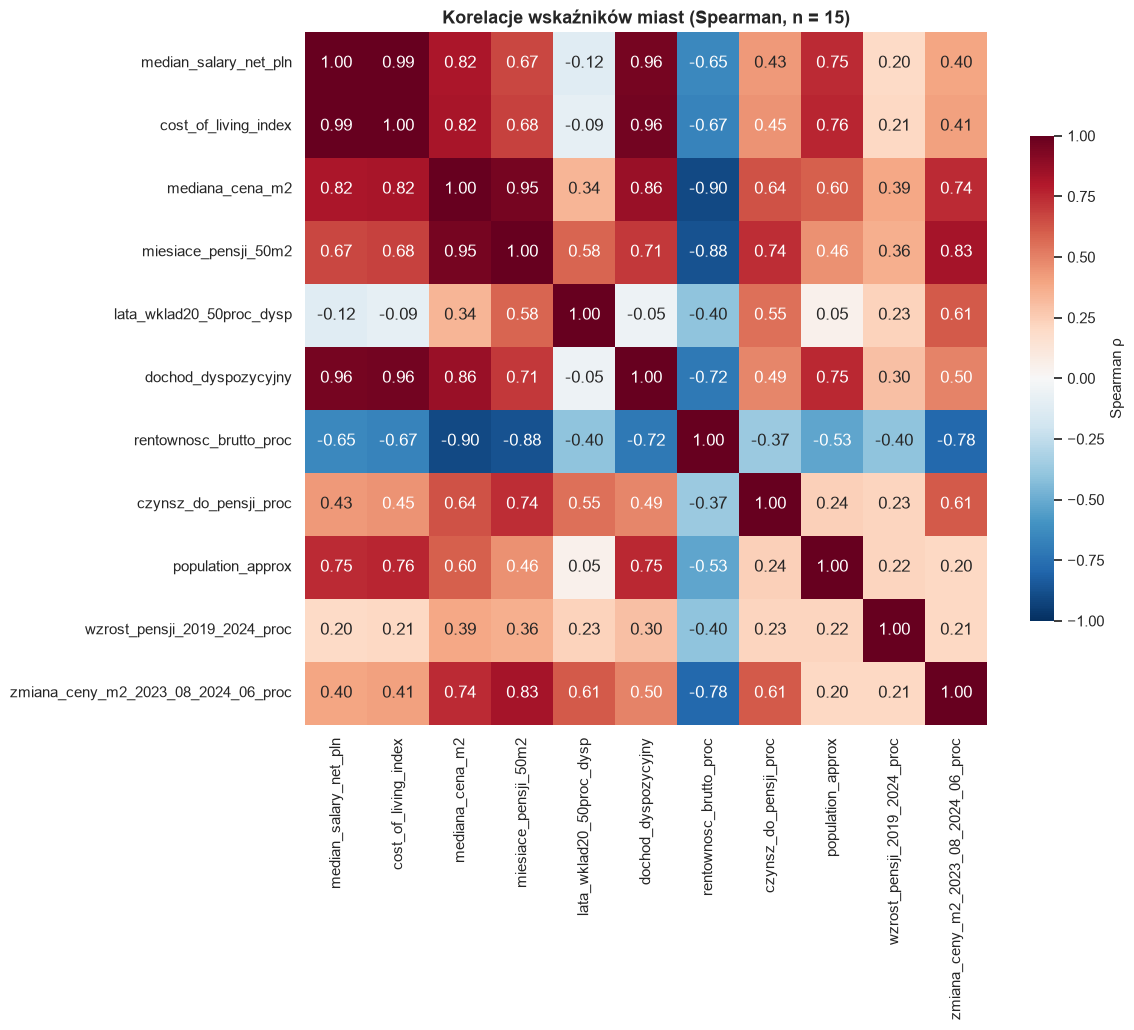

In [6]:
city_cols = ["median_salary_net_pln", "cost_of_living_index", "mediana_cena_m2", "miesiace_pensji_50m2",
             "lata_wklad20_50proc_dysp", "dochod_dyspozycyjny", "rentownosc_brutto_proc", "czynsz_do_pensji_proc",
             "population_approx", "wzrost_pensji_2019_2024_proc", "zmiana_ceny_m2_2023_08_2024_06_proc"]
city_corr = cities[city_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(city_corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", ax=ax,
            cbar_kws={"label": "Spearman ρ", "shrink": 0.7})
ax.set_title("Korelacje wskaźników miast (Spearman, n = 15)")
save_fig(fig, "04_korelacje_miasta")
plt.show()

In [7]:
rows = []
for a, b in [("median_salary_net_pln", "mediana_cena_m2"), ("median_salary_net_pln", "miesiace_pensji_50m2"),
             ("median_salary_net_pln", "lata_wklad20_50proc_dysp"), ("mediana_cena_m2", "rentownosc_brutto_proc"),
             ("cost_of_living_index", "mediana_cena_m2")]:
    rows.append({"para": f"{a} ~ {b}",
                 "Pearson": cities[a].corr(cities[b]),
                 "Spearman": cities[a].corr(cities[b], method="spearman"),
                 "Kendall": cities[a].corr(cities[b], method="kendall"),
                 "p (Spearman)": stats.spearmanr(cities[a], cities[b]).pvalue})
pd.DataFrame(rows).round(3)

,para,Pearson,Spearman,Kendall,p (Spearman)
0,median_salary_net_pln ~ mediana_cena_m2,0.91,0.82,0.64,0.00
1,median_salary_net_pln ~ miesiace_pensji_50m2,0.76,0.67,0.51,0.01
2,median_salary_net_pln ~ lata_wklad20_50proc_dysp,-0.02,-0.12,-0.05,0.67
3,mediana_cena_m2 ~ rentownosc_brutto_proc,-0.86,-0.90,-0.77,0.00
4,cost_of_living_index ~ mediana_cena_m2,0.92,0.82,0.66,0.00


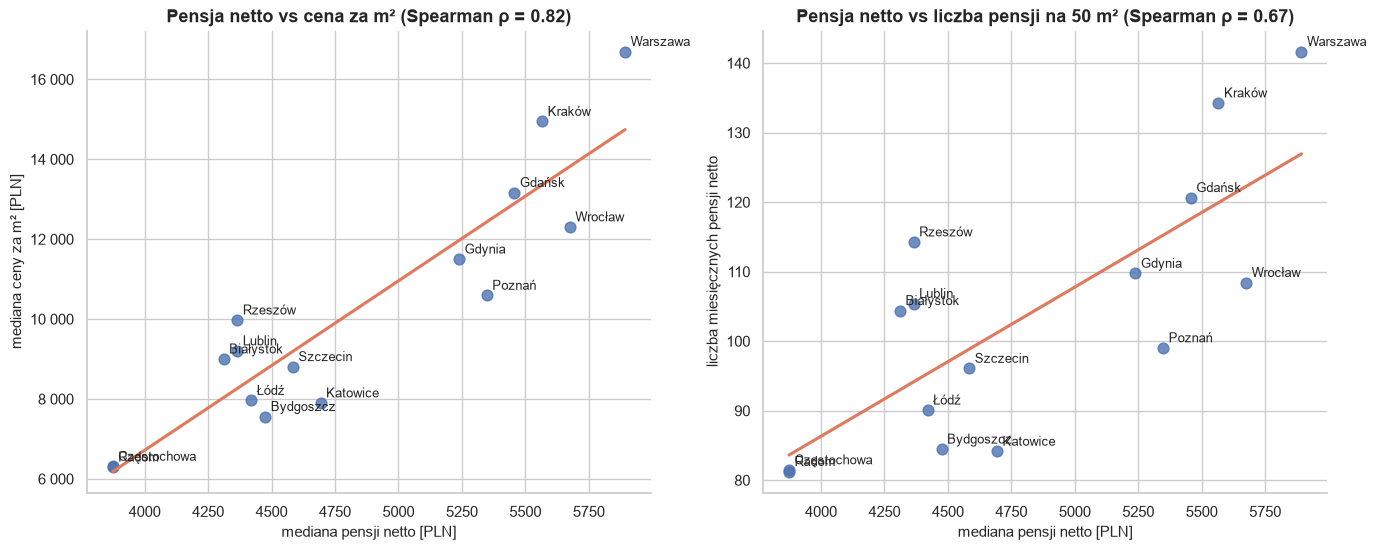

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, y, title in [(axes[0], "mediana_cena_m2", "Pensja netto vs cena za m²"),
                     (axes[1], "miesiace_pensji_50m2", "Pensja netto vs liczba pensji na 50 m²")]:
    sns.regplot(data=cities, x="median_salary_net_pln", y=y, ax=ax, ci=None, scatter_kws={"s": 60},
                line_kws={"color": "#e07a5f"})
    for _, r in cities.iterrows():
        ax.annotate(r["miasto"], (r["median_salary_net_pln"], r[y]), xytext=(4, 4), textcoords="offset points", fontsize=9)
    rho = cities["median_salary_net_pln"].corr(cities[y], method="spearman")
    ax.set_title(f"{title} (Spearman ρ = {rho:.2f})")
    ax.set_xlabel("mediana pensji netto [PLN]")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
axes[0].set_ylabel("mediana ceny za m² [PLN]")
axes[1].set_ylabel("liczba miesięcznych pensji netto")
save_fig(fig, "04_pensja_vs_dostepnosc")
plt.show()

**Wnioski (poziom miast):**
- Ceny mieszkań rosną **szybciej niż pensje**: pensja netto jest bardzo silnie skorelowana z ceną za m² (r = 0,91), ale też silnie i dodatnio z liczbą pensji potrzebnych na 50 m² (ρ = 0,67, p = 0,01).
  Oznacza to, że **w miastach o najwyższych zarobkach mieszkania są względnie mniej dostępne** — wyższa pensja nie rekompensuje wyższych cen.
- Po odjęciu kosztów życia (czas zbierania na wkład własny z dochodu dyspozycyjnego) korelacja z pensją **znika** (ρ ≈ −0,1) — w dużych miastach wyższy dochód dyspozycyjny równoważy wyższe ceny, a w mniejszych niższe ceny równoważą niski dochód.
- Rentowność najmu jest bardzo silnie ujemnie skorelowana z ceną za m² (ρ = −0,90) — w tańszych miastach inwestor uzyskuje wyższą stopę zwrotu brutto.
- Wskaźnik kosztów życia (zbiór 2) i cena za m² (zbiór 1) są silnie skorelowane (r = 0,92) — oba źródła są spójne.

## 4.4 Dobór atrybutów na podstawie korelacji

Atrybuty silnie skorelowane między sobą (|r| > 0,8) niosą zbliżoną informację (współliniowość). Do modeli zostawiamy po jednym z każdej pary.

In [9]:
abs_corr = pearson.abs().where(np.triu(np.ones(pearson.shape, dtype=bool), k=1))
high = abs_corr.stack().loc[lambda s: s > 0.6].sort_values(ascending=False).rename("|r|").to_frame()
high

|r|
restaurantDistance   pharmacyDistance     0.84
kindergartenDistance pharmacyDistance     0.83
squareMeters         rooms                0.82
postOfficeDistance   pharmacyDistance     0.79
schoolDistance       pharmacyDistance     0.79
kindergartenDistance restaurantDistance   0.78
schoolDistance       kindergartenDistance 0.77
postOfficeDistance   restaurantDistance   0.76
schoolDistance       restaurantDistance   0.75
                     postOfficeDistance   0.74
postOfficeDistance   kindergartenDistance 0.72
price                squareMeters         0.66
price_per_m2         price_index_city     0.65
floor                floorCount           0.64
price                price_per_m2         0.63
hasBalcony           amenities_count      0.61

- `price` ↔ `price_per_m2` / `price_index_city` — różne postacie zmiennej celu → w modelach używamy tylko jednej jako celu.
- `squareMeters` ↔ `rooms` — silnie powiązane; zostawiamy obie (pokoje niosą informację o układzie), ale w redukcji wymiarowości zostaną połączone w jedną składową.
- `floorCount` ↔ `hasElevator` — winda wynika z wysokości budynku.
- `amenities_count` jest sumą atrybutów binarnych — nie używamy jej razem z nimi.

## 4.5 Redukcja wymiarowości — PCA i LDA

| | **PCA** (analiza głównych składowych) | **LDA** (liniowa analiza dyskryminacyjna) |
|---|---|---|
| Typ | nienadzorowana (nie używa etykiet) | nadzorowana (wymaga klas) |
| Cel | maksymalizacja **wariancji** danych w nowych osiach | maksymalizacja **rozdzielenia klas** |
| Maks. liczba składowych | liczba atrybutów | liczba klas − 1 |
| Zastosowanie | kompresja, wizualizacja, usunięcie współliniowości, przygotowanie do grupowania | wizualizacja klas, przygotowanie do klasyfikacji |

Jako metodę główną wybieramy **PCA** (dane nie mają naturalnych etykiet, a składowe wykorzystamy później w grupowaniu i wizualizacji).
PCA wymaga **standaryzacji** — inaczej dominowałyby atrybuty o największej wariancji (np. rok budowy).

In [10]:
PCA_FEATURES = ["squareMeters", "rooms", "floor", "floorCount", "buildYear", "centreDistance", "poiCount",
                "schoolDistance", "clinicDistance", "postOfficeDistance", "kindergartenDistance",
                "restaurantDistance", "collegeDistance", "pharmacyDistance",
                "hasParkingSpace", "hasBalcony", "hasElevator", "hasSecurity", "hasStorageRoom"]

X = StandardScaler().fit_transform(sales[PCA_FEATURES])
pca_full = PCA(random_state=RANDOM_STATE).fit(X)
explained = pd.DataFrame({
    "składowa": [f"PC{i+1}" for i in range(len(PCA_FEATURES))],
    "wariancja wyjaśniona [%]": pca_full.explained_variance_ratio_ * 100,
    "skumulowana [%]": np.cumsum(pca_full.explained_variance_ratio_) * 100,
    "wartość własna": pca_full.explained_variance_,
})
n80 = int((explained["skumulowana [%]"] >= 80).idxmax()) + 1
kaiser = int((explained["wartość własna"] > 1).sum())
print(f"Liczba składowych wyjaśniających ≥80% wariancji: {n80} (z {len(PCA_FEATURES)})")
print(f"Kryterium Kaisera (wartość własna > 1): {kaiser} składowych")
explained.head(10).round(2)

Liczba składowych wyjaśniających ≥80% wariancji: 9 (z 19)
Kryterium Kaisera (wartość własna > 1): 6 składowych


,składowa,wariancja wyjaśniona [%],skumulowana [%],wartość własna
0,PC1,27.38,27.38,5.20
1,PC2,12.42,39.80,2.36
2,PC3,10.23,50.03,1.94
3,PC4,8.84,58.88,1.68
4,PC5,6.45,65.33,1.23
5,PC6,5.36,70.69,1.02
6,PC7,4.74,75.43,0.90
7,PC8,4.44,79.87,0.84
8,PC9,3.25,83.12,0.62
9,PC10,2.95,86.08,0.56


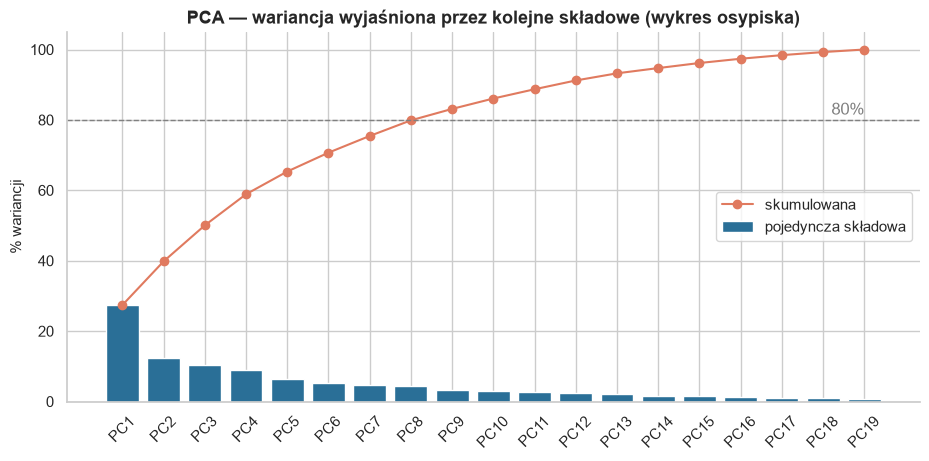

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(explained["składowa"], explained["wariancja wyjaśniona [%]"], color="#2a6f97", label="pojedyncza składowa")
ax.plot(explained["składowa"], explained["skumulowana [%]"], marker="o", color="#e07a5f", label="skumulowana")
ax.axhline(80, color="gray", ls="--", lw=1)
ax.text(len(PCA_FEATURES) - 1, 81.5, "80%", color="gray", ha="right")
ax.set_title("PCA — wariancja wyjaśniona przez kolejne składowe (wykres osypiska)")
ax.set_ylabel("% wariancji")
ax.legend(loc="center right")
ax.tick_params(axis="x", rotation=45)
save_fig(fig, "04_pca_wariancja")
plt.show()

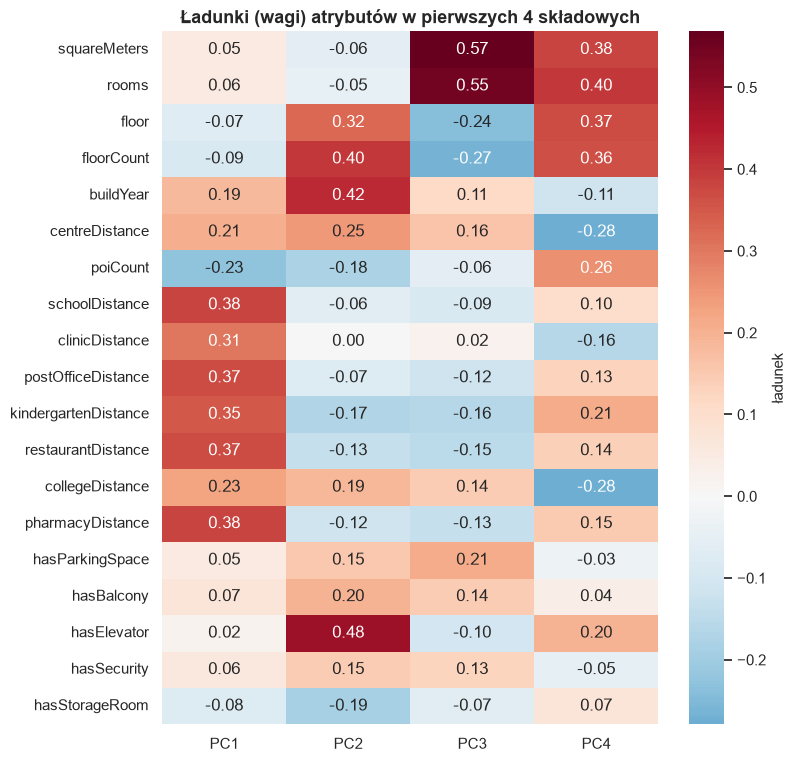

PC1 → pharmacyDistance (+0.38), schoolDistance (+0.38), restaurantDistance (+0.37), postOfficeDistance (+0.37)
PC2 → hasElevator (+0.48), buildYear (+0.42), floorCount (+0.40), floor (+0.32)
PC3 → squareMeters (+0.57), rooms (+0.55), floorCount (-0.27), floor (-0.24)
PC4 → rooms (+0.40), squareMeters (+0.38), floor (+0.37), floorCount (+0.36)


In [12]:
loadings = pd.DataFrame(pca_full.components_[:4].T, index=PCA_FEATURES, columns=["PC1", "PC2", "PC3", "PC4"])
fig, ax = plt.subplots(figsize=(8, 9))
sns.heatmap(loadings, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=ax, cbar_kws={"label": "ładunek"})
ax.set_title("Ładunki (wagi) atrybutów w pierwszych 4 składowych")
save_fig(fig, "04_pca_ladunki")
plt.show()

for pc in loadings.columns:
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(pc, "→", ", ".join(f"{f} ({loadings.loc[f, pc]:+.2f})" for f in top))

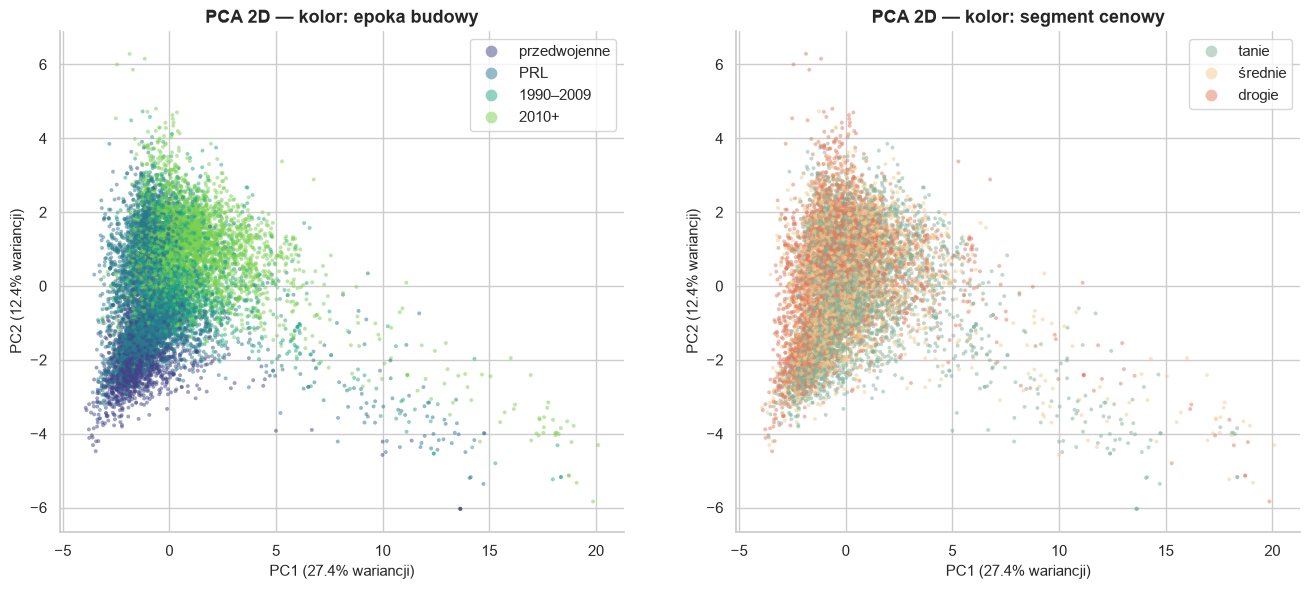

In [13]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca2.fit_transform(X)
plot_df = sales[["segment_cenowy", "strefa", "epoka_budowy"]].assign(PC1=Z[:, 0], PC2=Z[:, 1]).sample(12000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="epoka_budowy", s=8, alpha=0.5, linewidth=0, ax=axes[0],
                hue_order=["przedwojenne", "PRL", "1990–2009", "2010+"], palette="viridis")
axes[0].set_title("PCA 2D — kolor: epoka budowy")
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="segment_cenowy", s=8, alpha=0.5, linewidth=0, ax=axes[1],
                hue_order=["tanie", "średnie", "drogie"], palette=["#81b29a", "#f2cc8f", "#e07a5f"])
axes[1].set_title("PCA 2D — kolor: segment cenowy")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%} wariancji)")
    ax.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%} wariancji)")
    ax.legend(markerscale=3, title=None)
save_fig(fig, "04_pca_2d")
plt.show()

### LDA (porównawczo)
LDA wykorzystuje etykiety — szukamy osi, które najlepiej rozdzielają **segmenty cenowe** (3 klasy → maks. 2 składowe).

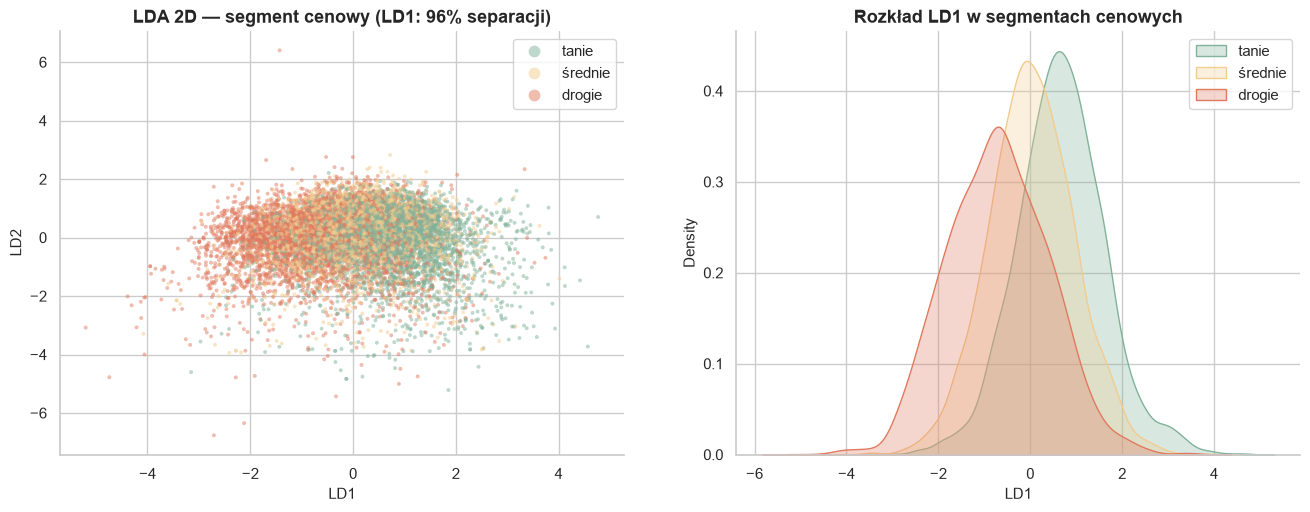

Atrybuty najsilniej różnicujące segmenty (LD1):
centreDistance        0.59
buildYear            -0.55
hasElevator          -0.33
poiCount             -0.32
restaurantDistance    0.32
squareMeters          0.31


In [14]:
lda = LinearDiscriminantAnalysis(n_components=2)
Z_lda = lda.fit_transform(X, sales["segment_cenowy"])
lda_df = pd.DataFrame({"LD1": Z_lda[:, 0], "LD2": Z_lda[:, 1], "segment_cenowy": sales["segment_cenowy"]}) \
           .sample(12000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(data=lda_df, x="LD1", y="LD2", hue="segment_cenowy", s=8, alpha=0.5, linewidth=0, ax=axes[0],
                hue_order=["tanie", "średnie", "drogie"], palette=["#81b29a", "#f2cc8f", "#e07a5f"])
axes[0].set_title(f"LDA 2D — segment cenowy (LD1: {lda.explained_variance_ratio_[0]:.0%} separacji)")
axes[0].legend(markerscale=3)
for seg, color in zip(["tanie", "średnie", "drogie"], ["#81b29a", "#f2cc8f", "#e07a5f"]):
    sns.kdeplot(lda_df.loc[lda_df["segment_cenowy"] == seg, "LD1"], ax=axes[1], label=seg, color=color, fill=True, alpha=0.3)
axes[1].set_title("Rozkład LD1 w segmentach cenowych")
axes[1].legend()
save_fig(fig, "04_lda_2d")
plt.show()

lda_coef = pd.Series(lda.scalings_[:, 0], index=PCA_FEATURES).sort_values(key=abs, ascending=False)
print("Atrybuty najsilniej różnicujące segmenty (LD1):")
print(lda_coef.head(6).round(3).to_string())

In [15]:
pca_out = sales[["id", "city"]].copy()
pca_k = PCA(n_components=n80, random_state=RANDOM_STATE).fit_transform(X)
for i in range(n80):
    pca_out[f"PC{i+1}"] = pca_k[:, i].round(5)
pca_out.to_csv(PROCESSED_DIR / "oferty_pca.csv", index=False)
print(f"Zapisano {pca_out.shape} → data/processed/oferty_pca.csv")

Zapisano (91292, 11) → data/processed/oferty_pca.csv


## 4.6 Analiza wyników i podsumowanie etapu

**Korelacja:**
- Na poziomie ofert cenę (względem miasta) najmocniej różnicują: **bliskość centrum, winda, liczba usług w okolicy, nowość budynku**; większe mieszkania są tańsze za m².
- Pojedyncze korelacje są słabe/umiarkowane, a część zależności nieliniowa → w modelach warto użyć metody nieliniowej i wielowymiarowej (drzewo decyzyjne — etap 5).
- Silna współliniowość odległości do usług (szkoła, apteka, poczta, restauracja: r = 0,72–0,84) uzasadnia redukcję wymiarowości.
- Na poziomie miast: im wyższe zarobki, tym **wyższa** cena za m² i **gorsza** względna dostępność (więcej pensji na 50 m²). Wyższa rentowność najmu występuje w tańszych miastach.

**Redukcja wymiarowości:**
- **PCA**: 19 atrybutów można zastąpić **9 składowymi** wyjaśniającymi 83% wariancji (kryterium Kaisera: 6 składowych). Pierwsze składowe są interpretowalne:
  **PC1 (27%)** — *oddalenie od usług* (wszystkie odległości do POI), **PC2 (12%)** — *nowoczesny, wysoki budynek* (winda, rok budowy, liczba pięter),
  **PC3 (10%)** — *wielkość mieszkania* (metraż, pokoje).
- Na wykresie PCA 2D epoki budowy tworzą wyraźne obszary, ale segmenty cenowe się nakładają — **PCA nie jest projektowane do rozdzielania klas**.
- **LDA** (nadzorowane) lepiej rozdziela segmenty cenowe na osi LD1, budowanej głównie z odległości od centrum i roku budowy; segmenty nadal częściowo się nakładają → cena zależy też od czynników, których nie ma w danych (stan techniczny, widok, wykończenie).
- Składowe PCA zapisano do `oferty_pca.csv` (wykorzystanie w grupowaniu — etap 6).